<a href="https://colab.research.google.com/github/gatemediang/sentiment-analysis-imdb/blob/main/imdb_sentiment_analysis_fine_tuned.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
!pip install transformers datasets accelerate -q

print("\n✅ Libraries installed successfully!")


✅ Libraries installed successfully!


In [12]:
#Import libraries
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    pipeline
)
from datasets import Dataset, load_dataset
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("✅ All libraries imported successfully!")
print("="*70)

✅ All libraries imported successfully!


In [13]:
# Log in to Hugging Face with the HF_TOKEN Colab secret

from google.colab import userdata
from huggingface_hub import login, whoami

login(token=userdata.get("HF_TOKEN"))
print("Logged in as:", whoami()["name"])

Logged in as: gatemediang


In [14]:
# Upload, check and clean the fresh dataset

import pandas as pd
from google.colab import files

print("Upload your fresh CSV (columns: text,label with labels 0 and 1)")
uploaded = files.upload()
csv_name = next(iter(uploaded))      # Colab may rename it, e.g. "file (1).csv"

df = pd.read_csv(csv_name)

missing = {"text", "label"} - set(df.columns)
if missing:
    raise ValueError(f"CSV is missing column(s): {missing}")

df = df[["text", "label"]]
before = len(df)
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"].str.len() > 0]                 # drop empty rows
df = df[df["label"].isin([0, 1])]                 # drop bad labels
df = df.drop_duplicates(subset="text")            # drop repeated reviews
df["label"] = df["label"].astype(int)
df = df.reset_index(drop=True)

print(f"Rows: {before} uploaded, {len(df)} after cleaning")
print(df["label"].value_counts().rename({0: "Negative", 1: "Positive"}))

# Saved under the name the evaluation cell expects, so its split matches this one
df.to_csv("slang_reviews.csv", index=False)


Upload your fresh CSV (columns: text,label with labels 0 and 1)


Saving slang_reviews.csv to slang_reviews (1).csv
Rows: 341 uploaded, 341 after cleaning
label
Positive    173
Negative    168
Name: count, dtype: int64


In [15]:
# Build train/test sets (slang test set stays slang-only)

from datasets import Dataset, Value, concatenate_datasets, load_dataset

IMDB_TRAIN_SAMPLE = 800   # ordinary reviews mixed into training

# Same 80/20 split, same seed, as the evaluation cell
slang_split = Dataset.from_pandas(df).train_test_split(test_size=0.2, seed=42)

imdb_train = (
    load_dataset("stanfordnlp/imdb", split="train")
    .shuffle(seed=42)
    .select(range(IMDB_TRAIN_SAMPLE))
    .cast_column("label", Value("int64"))          # match the slang label type
)

train_ds = concatenate_datasets([slang_split["train"], imdb_train]).shuffle(seed=42)
test_ds = slang_split["test"]

print(f"Training: {len(slang_split['train'])} slang + {len(imdb_train)} IMDB = {len(train_ds)}")
print(f"Test (slang only): {len(test_ds)}")


Training: 272 slang + 800 IMDB = 1072
Test (slang only): 69


In [16]:
# Load the base model and tokenize

from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding)

BASE_MODEL = "distilbert-base-uncased-finetuned-sst-2-english"
MAX_LENGTH = 256   # slang reviews are short; IMDB reviews get truncated here

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
model = AutoModelForSequenceClassification.from_pretrained(BASE_MODEL, num_labels=2)


def tokenize(batch):
    # No padding here: the data collator pads each batch to its longest item
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)


tokenized_train = train_ds.map(tokenize, batched=True)
tokenized_test = test_ds.map(tokenize, batched=True)
collator = DataCollatorWithPadding(tokenizer=tokenizer)
print("Tokenization done")


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Map:   0%|          | 0/69 [00:00<?, ? examples/s]

Tokenization done


In [17]:
# Fine-tune

import numpy as np
import torch
from sklearn.metrics import accuracy_score
from transformers import Trainer, TrainingArguments


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return {"accuracy": accuracy_score(labels, np.argmax(logits, axis=1))}


training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=15,
    eval_strategy="epoch",        # report test accuracy, but don't pick a checkpoint with it
    save_strategy="no",
    logging_steps=10,
    fp16=torch.cuda.is_available(),
    seed=42,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    data_collator=collator,
    compute_metrics=compute_metrics,
)

trainer.train()
print(trainer.evaluate())



Epoch,Training Loss,Validation Loss,Accuracy
1,0.344746,0.397028,0.826087
2,0.221833,0.407039,0.840580


Training Loss,Validation Loss,Epoch,Accuracy
0.221833,0.407039,2,0.840580


{'eval_loss': 0.40703868865966797, 'eval_accuracy': 0.8405797101449275}


In [18]:
REPO_ID = "gatemediang/distilbert-slang-sentiment"

model.push_to_hub(REPO_ID, commit_message="Retrained on fresh slang data mixed with IMDB")
tokenizer.push_to_hub(REPO_ID, commit_message="Upload tokenizer")
print(f"Done. View it at https://huggingface.co/{REPO_ID}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...9ixg193/model.safetensors:   6%|5         | 15.9MB /  268MB            

Validating                    :           |   0%            

Done. View it at https://huggingface.co/gatemediang/distilbert-slang-sentiment


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Before fine-tuning | Slang test set
Accuracy: 0.841

              precision    recall  f1-score   support

    Negative      0.865     0.842     0.853        38
    Positive      0.812     0.839     0.825        31

    accuracy                          0.841        69
   macro avg      0.839     0.840     0.839        69
weighted avg      0.841     0.841     0.841        69



Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Before fine-tuning | IMDB sample (n=500)
Accuracy: 0.890

              precision    recall  f1-score   support

    Negative      0.873     0.917     0.894       254
    Positive      0.910     0.862     0.885       246

    accuracy                          0.890       500
   macro avg      0.891     0.890     0.890       500
weighted avg      0.891     0.890     0.890       500



Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


After fine-tuning | Slang test set
Accuracy: 0.841

              precision    recall  f1-score   support

    Negative      0.865     0.842     0.853        38
    Positive      0.812     0.839     0.825        31

    accuracy                          0.841        69
   macro avg      0.839     0.840     0.839        69
weighted avg      0.841     0.841     0.841        69



Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


After fine-tuning | IMDB sample (n=500)
Accuracy: 0.892

              precision    recall  f1-score   support

    Negative      0.888     0.902     0.895       254
    Positive      0.897     0.882     0.889       246

    accuracy                          0.892       500
   macro avg      0.892     0.892     0.892       500
weighted avg      0.892     0.892     0.892       500


Accuracy summary
                    Slang test set  IMDB sample (n=500)
Before fine-tuning           0.841                0.890
After fine-tuning            0.841                0.892


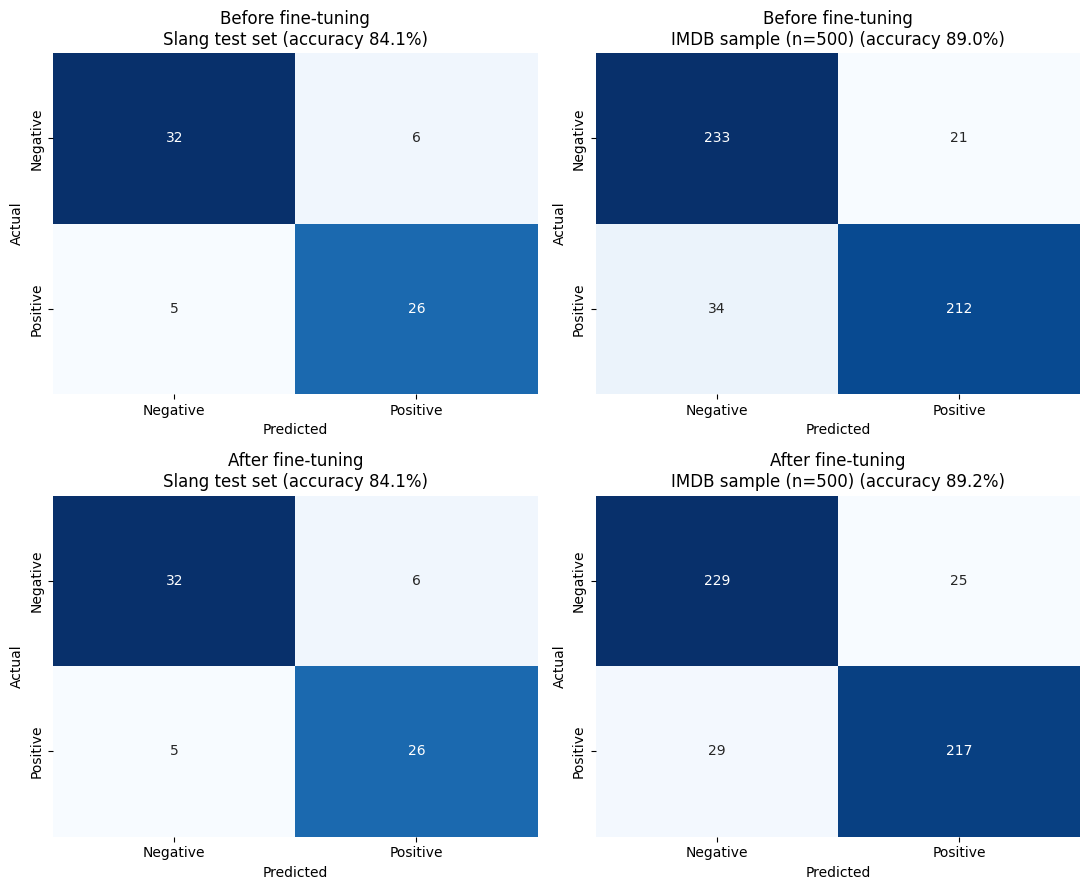

In [19]:
# =============================================================================
# Evaluate BEFORE vs AFTER fine-tuning
# =============================================================================
# Rebuilds the exact same 80/20 split used in training (same CSV, seed=42),
# then scores the base model and the fine-tuned model on the held-out 66 reviews.
# Also scores both on a sample of the real IMDB test set, to check that
# fine-tuning on slang did not damage performance on ordinary reviews.
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import Dataset, load_dataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from transformers import pipeline

BASE_MODEL = "distilbert-base-uncased-finetuned-sst-2-english"
FINE_TUNED = REPO_ID          # or MODEL_DIR to use the local copy
IMDB_SAMPLE = 500             # lower this if running on CPU is slow
DEVICE = 0 if torch.cuda.is_available() else -1
CLASS_NAMES = ["Negative", "Positive"]

# Same split as training
df = pd.read_csv("slang_reviews.csv")
split = Dataset.from_pandas(df).train_test_split(test_size=0.2, seed=42)
slang_texts = split["test"]["text"]
slang_labels = split["test"]["label"]

# Random sample of the real IMDB test set
imdb = load_dataset("stanfordnlp/imdb", split="test").shuffle(seed=42).select(range(IMDB_SAMPLE))
imdb_texts = imdb["text"]
imdb_labels = imdb["label"]


def label_to_int(label: str) -> int:
    """Map 'POSITIVE'/'LABEL_1' to 1 and 'NEGATIVE'/'LABEL_0' to 0."""
    return 1 if label.upper() in ("POSITIVE", "LABEL_1") else 0


def evaluate(model_id, texts, labels, title):
    """Run the model on texts, print the metrics, return accuracy and confusion matrix."""
    clf = pipeline("text-classification", model=model_id, device=DEVICE)
    outputs = clf(list(texts), batch_size=16, truncation=True, max_length=512)
    preds = [label_to_int(o["label"]) for o in outputs]

    acc = accuracy_score(labels, preds)
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")
    print(f"Accuracy: {acc:.3f}\n")
    print(classification_report(labels, preds, target_names=CLASS_NAMES, digits=3))
    return acc, confusion_matrix(labels, preds)


results = {}
for model_tag, model_id in [("Before fine-tuning", BASE_MODEL), ("After fine-tuning", FINE_TUNED)]:
    for data_tag, texts, labels in [
        ("Slang test set", slang_texts, slang_labels),
        (f"IMDB sample (n={IMDB_SAMPLE})", imdb_texts, imdb_labels),
    ]:
        results[(model_tag, data_tag)] = evaluate(model_id, texts, labels, f"{model_tag} | {data_tag}")

# Accuracy summary table
summary = pd.DataFrame(
    {data: {m: results[(m, data)][0] for m in ("Before fine-tuning", "After fine-tuning")}
     for data in ("Slang test set", f"IMDB sample (n={IMDB_SAMPLE})")}
).round(3)
print("\nAccuracy summary")
print(summary)
summary.to_csv("accuracy_summary.csv")

# Confusion matrix heatmaps, 2 x 2 grid
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, model_tag in enumerate(("Before fine-tuning", "After fine-tuning")):
    for col, data_tag in enumerate(("Slang test set", f"IMDB sample (n={IMDB_SAMPLE})")):
        acc, cm = results[(model_tag, data_tag)]
        ax = axes[row, col]
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
        ax.set_title(f"{model_tag}\n{data_tag} (accuracy {acc:.1%})")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
from google.colab import files

files.download("confusion_matrices.png")
files.download("accuracy_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>